# LAST EXIT — Intelligent Disaster Evacuation System
**Aim:** coordinate rescue teams and evacuate people safely during a flood.

Pipeline: Knowledge base → Rules → Uncertainty → Allocation → Multi-agent (CNP) → Simulation.

Requires: `numpy pandas networkx matplotlib scipy`

In [16]:
import math, copy, random
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.optimize import linprog
from IPython.display import display

random.seed(42)
np.random.seed(42)
pd.set_option('display.width', 160)

## 1. Knowledge Representation
**Frames** (slot–value objects) for areas, shelters and teams, plus a **semantic network** (subject–relation–object triples) over a road graph.

In [17]:
# ---------- Frames ----------
NODES = {  # node: (x km, y km, type)
    'HQ': (3, 1, 'base'), 'Marina': (5, 10, 'base'),
    'A1': (1, 7, 'area'), 'A2': (4, 8, 'area'), 'A3': (7, 9, 'area'),
    'A4': (3, 4, 'area'), 'A5': (6, 5, 'area'), 'A6': (9, 6, 'area'),
    'S1': (0, 2, 'shelter'), 'S2': (6, 1, 'shelter'), 'S3': (10, 3, 'shelter'), 'S4': (2, -1, 'shelter'),
    'J1': (2, 6, 'junction'), 'J2': (6, 7, 'junction'), 'J3': (5, 3, 'junction'), 'J4': (8, 4, 'junction'),
}

AREAS = {  # flood_readings = noisy sensor values (m)
    'A1': dict(name='Riverside',    population=220, vulnerable=0.35, injured=12, flood_readings=[2.1, 2.4, 1.9]),
    'A2': dict(name='Lowtown',      population=300, vulnerable=0.20, injured=5,  flood_readings=[1.6, 1.2, 1.5]),
    'A3': dict(name='Harbor',       population=180, vulnerable=0.30, injured=8,  flood_readings=[2.6, 2.8, 2.5]),
    'A4': dict(name='Old Market',   population=250, vulnerable=0.15, injured=0,  flood_readings=[0.8, 1.0, 0.6]),
    'A5': dict(name='Mill Colony',  population=200, vulnerable=0.40, injured=3,  flood_readings=[1.1, 1.4, 0.9]),
    'A6': dict(name='Valley Farms', population=120, vulnerable=0.10, injured=0,  flood_readings=[0.4, 0.3, 0.5]),
}

SHELTERS = {
    'S1': dict(name='North School',  capacity=350),
    'S2': dict(name='City Stadium',  capacity=600),
    'S3': dict(name='Hilltop Hall',  capacity=250),
    'S4': dict(name='Community Ctr', capacity=250),
}

TEAMS = {
    'T1': dict(name='Truck-Alpha', kind='truck',     base='HQ',     capacity=40, speed=40,  medical=False, fuel_per_km=0.30),
    'T2': dict(name='Truck-Bravo', kind='truck',     base='HQ',     capacity=40, speed=40,  medical=False, fuel_per_km=0.30),
    'T3': dict(name='Bus-Charlie', kind='truck',     base='HQ',     capacity=60, speed=35,  medical=False, fuel_per_km=0.35),
    'B1': dict(name='Boat-Delta',  kind='boat',      base='Marina', capacity=20, speed=20,  medical=False, fuel_per_km=0.50),
    'B2': dict(name='Boat-Echo',   kind='boat',      base='Marina', capacity=20, speed=20,  medical=False, fuel_per_km=0.50),
    'B3': dict(name='Boat-Fox',    kind='boat',      base='Marina', capacity=20, speed=20,  medical=False, fuel_per_km=0.50),
    'H1': dict(name='Heli-Golf',   kind='heli',      base='HQ',     capacity=8,  speed=150, medical=True,  fuel_per_km=3.00),
    'M1': dict(name='Medic-Hotel', kind='ambulance', base='HQ',     capacity=6,  speed=50,  medical=True,  fuel_per_km=0.20),
}

ROADS = [  # (u, v, condition 0-10, field reports [(says_blocked, reliability)])
    ('A1', 'J1', 6, [(False, 0.8)]),
    ('A1', 'S1', 3, [(True, 0.7)]),
    ('A2', 'J1', 5, [(False, 0.7)]),
    ('A2', 'J2', 4, [(True, 0.6), (False, 0.7)]),
    ('A3', 'J2', 2, [(True, 0.8), (True, 0.6)]),
    ('A3', 'A6', 3, [(True, 0.8)]),
    ('J1', 'A4', 7, [(False, 0.9)]),
    ('J2', 'A5', 6, [(False, 0.8)]),
    ('A5', 'A6', 7, [(False, 0.8)]),
    ('A5', 'J3', 8, []),
    ('A4', 'J3', 8, []),
    ('A4', 'S1', 7, [(False, 0.9)]),
    ('A6', 'J4', 6, [(False, 0.7)]),
    ('J3', 'S2', 9, []),
    ('J3', 'HQ', 9, []),
    ('HQ', 'S1', 8, []),
    ('HQ', 'S2', 9, []),
    ('HQ', 'S4', 9, []),
    ('S1', 'S4', 8, []),
    ('J4', 'S3', 8, []),
    ('J4', 'S2', 7, []),
    ('Marina', 'A2', 5, []),
    ('Marina', 'A3', 3, [(True, 0.7), (True, 0.6)]),
    ('Marina', 'J2', 5, []),
]

RESOURCES = dict(fuel=900.0, medical_kits=25)                  # shared pools
PRIORITY_W = dict(critical=4, high=3, medium=2, low=1)
DEADLINE = dict(critical=180, high=240, medium=360, low=480)   # safe-evacuation deadline (min)

In [18]:
def make_world(severity=0.0):
    '''Instantiate frames + road graph. severity (0-1) worsens flood, roads and injuries.'''
    w = dict(areas=copy.deepcopy(AREAS), shelters=copy.deepcopy(SHELTERS),
             teams=copy.deepcopy(TEAMS), resources=dict(RESOURCES), _cache={})
    for d in w['areas'].values():
        d['flood_readings'] = [r + 0.8 * severity for r in d['flood_readings']]
        d['injured'] = int(round(d['injured'] * (1 + severity)))
        d['injured_left'] = d['injured']
    for d in w['shelters'].values():
        d['open'], d['remaining'] = True, d['capacity']
    G = nx.Graph()
    for n, (x, y, kind) in NODES.items():
        G.add_node(n, kind=kind)
    for u, v, cond, reps in ROADS:
        c = max(0.0, cond - 2 * severity)
        G.add_edge(u, v, dist=round(1.2 * math.dist(NODES[u][:2], NODES[v][:2]), 2),
                   condition=c, reports=list(reps), p_blocked=1.0 if c <= 2 else 0.0)  # crisp belief for now
    w['G'] = G
    return w

def team_graph(w, mode='ground', thresh=0.6):
    '''Usable roads: boats ignore flooding, ground teams avoid roads likely blocked.'''
    H = nx.Graph()
    H.add_nodes_from(w['G'].nodes)
    for u, v, e in w['G'].edges(data=True):
        if not e.get('closed') and (mode == 'boat' or e['p_blocked'] <= thresh):
            H.add_edge(u, v, **e)
    return H

# ---------- Semantic network (triples) ----------
def build_triples(w):
    T = []
    for t, d in w['teams'].items():
        T += [(t, 'is_a', d['kind']), (t, 'stationed_at', d['base'])]
        if d['medical']:
            T.append((t, 'has_capability', 'medical'))
    for a in w['areas']:
        T.append((a, 'is_a', 'AffectedArea'))
        dist = nx.single_source_dijkstra_path_length(w['G'], a, weight='dist')
        T.append((a, 'nearest_shelter', min(w['shelters'], key=lambda s: dist.get(s, math.inf))))
    for s in w['shelters']:
        T.append((s, 'is_a', 'Shelter'))
    for u, v in w['G'].edges:
        T.append((u, 'road_to', v))
    return T

def query(T, s=None, p=None, o=None):
    return [t for t in T if (s is None or t[0] == s) and (p is None or t[1] == p) and (o is None or t[2] == o)]

COL = dict(base='tab:blue', area='tab:red', shelter='tab:green', junction='gray')

def draw_map(w, ax, title, trips=None):
    G = w['G']
    pos = {n: NODES[n][:2] for n in G}
    ecol = ['black' if e.get('closed') else plt.cm.RdYlGn(1 - e['p_blocked']) for _, _, e in G.edges(data=True)]
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=ecol, width=2.5)
    if trips:
        flow = {}
        for tr in trips:
            for e in zip(tr['path'], tr['path'][1:]):
                if G.has_edge(*e):
                    k = tuple(sorted(e))
                    flow[k] = flow.get(k, 0) + tr['people']
        if flow:
            m = max(flow.values())
            nx.draw_networkx_edges(G, pos, ax=ax, edgelist=list(flow), edge_color='royalblue', alpha=0.45,
                                   width=[1 + 9 * flow[k] / m for k in flow])
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=500, node_color=[COL[NODES[n][2]] for n in G])
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_color='white')
    for k, c in COL.items():
        ax.scatter([], [], c=c, label=k)
    ax.legend(loc='lower right', fontsize=8)
    ax.set_title(title)
    ax.axis('off')

,name,population,vulnerable,injured,flood_readings
A1,Riverside,220,0.35,12,"[2.1, 2.4, 1.9]"
A2,Lowtown,300,0.2,5,"[1.6, 1.2, 1.5]"
A3,Harbor,180,0.3,8,"[2.6, 2.8, 2.5]"
A4,Old Market,250,0.15,0,"[0.8, 1.0, 0.6]"
A5,Mill Colony,200,0.4,3,"[1.1, 1.4, 0.9]"
A6,Valley Farms,120,0.1,0,"[0.4, 0.3, 0.5]"


,name,capacity
S1,North School,350
S2,City Stadium,600
S3,Hilltop Hall,250
S4,Community Ctr,250


,name,kind,base,capacity,speed,medical,fuel_per_km
T1,Truck-Alpha,truck,HQ,40,40,False,0.3
T2,Truck-Bravo,truck,HQ,40,40,False,0.3
T3,Bus-Charlie,truck,HQ,60,35,False,0.35
B1,Boat-Delta,boat,Marina,20,20,False,0.5
B2,Boat-Echo,boat,Marina,20,20,False,0.5
B3,Boat-Fox,boat,Marina,20,20,False,0.5
H1,Heli-Golf,heli,HQ,8,150,True,3.0
M1,Medic-Hotel,ambulance,HQ,6,50,True,0.2


58 triples, e.g. [('T1', 'is_a', 'truck'), ('T1', 'stationed_at', 'HQ'), ('T2', 'is_a', 'truck'), ('T2', 'stationed_at', 'HQ')]
Medical-capable teams: ['H1', 'M1']
Teams at Marina      : ['B1', 'B2', 'B3']
Nearest shelters     : {'A1': 'S1', 'A2': 'S1', 'A3': 'S3', 'A4': 'S1', 'A5': 'S2', 'A6': 'S3'}


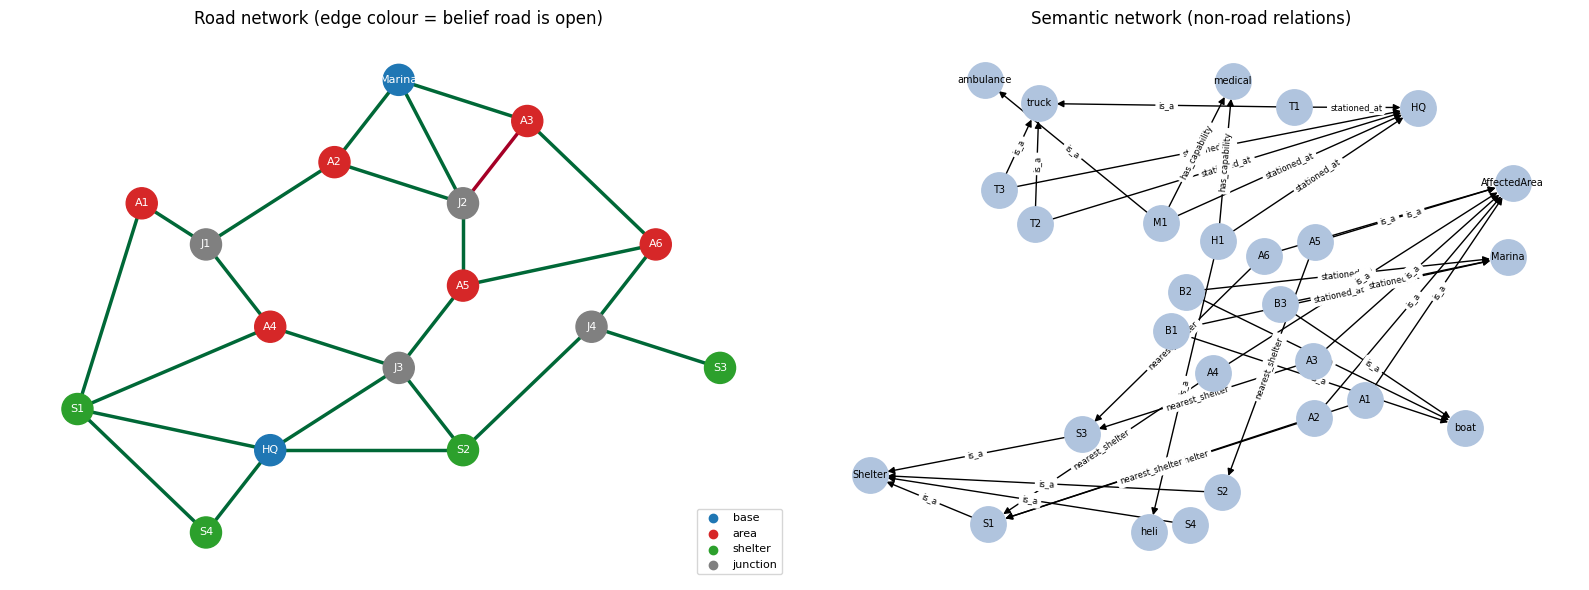

In [19]:
W0 = make_world()
TRIPLES = build_triples(W0)
display(pd.DataFrame(AREAS).T, pd.DataFrame(SHELTERS).T, pd.DataFrame(TEAMS).T)

print(len(TRIPLES), 'triples, e.g.', TRIPLES[:4])
print('Medical-capable teams:', [t[0] for t in query(TRIPLES, p='has_capability', o='medical')])
print('Teams at Marina      :', [t[0] for t in query(TRIPLES, p='stationed_at', o='Marina')])
print('Nearest shelters     :', {t[0]: t[2] for t in query(TRIPLES, p='nearest_shelter')})

fig, axs = plt.subplots(1, 2, figsize=(16, 6))
draw_map(W0, axs[0], 'Road network (edge colour = belief road is open)')
KG = nx.DiGraph()
for s, p, o in TRIPLES:
    if p != 'road_to':
        KG.add_edge(s, o, relation=p)
kpos = nx.spring_layout(KG, seed=3, k=0.9)
nx.draw(KG, kpos, ax=axs[1], with_labels=True, node_size=650, node_color='lightsteelblue', font_size=7, arrowsize=10)
nx.draw_networkx_edge_labels(KG, kpos, edge_labels=nx.get_edge_attributes(KG, 'relation'), font_size=6, ax=axs[1])
axs[1].set_title('Semantic network (non-road relations)')
plt.tight_layout()
plt.show()

## 2. Rule-Based Reasoning
IF–THEN rules. **Forward chaining** derives priorities and actions; **backward chaining** proves specific goals.

In [20]:
# ---------- Inference engine ----------
def match(pattern, fact, b):
    if len(pattern) != len(fact):
        return None
    b = dict(b)
    for p, f in zip(pattern, fact):
        if isinstance(p, str) and p.startswith('?'):
            if b.get(p, f) != f:
                return None
            b[p] = f
        elif p != f:
            return None
    return b

def match_all(conds, facts, b=None):
    b = b or {}
    if not conds:
        yield b
        return
    for f in facts:
        nb = match(conds[0], f, b)
        if nb is not None:
            yield from match_all(conds[1:], facts, nb)

def subst(p, b):
    return tuple(b.get(x, x) for x in p)

def forward_chain(facts, rules):
    facts, fired, changed = set(facts), [], True
    while changed:
        changed = False
        for r in rules:
            for b in list(match_all(r['if'], facts)):
                for c in r['then']:
                    new = subst(c, b)
                    if new not in facts:
                        facts.add(new)
                        fired.append((r['name'], new))
                        changed = True
    return facts, fired

def backward_chain(goal, facts, rules):
    if goal in facts:
        return True
    for r in rules:
        for c in r['then']:
            b = match(c, goal, {})
            if b is not None and all(backward_chain(subst(p, b), facts, rules) for p in r['if']):
                return True
    return False

# ---------- Rule base ----------
def rule(name, cond, then):
    return {'name': name, 'if': cond, 'then': then}

RULES = [
    rule('R1 high flood & vulnerable -> critical', [('flood', '?a', 'high'), ('vulnerable', '?a', 'yes')], [('priority', '?a', 'critical')]),
    rule('R2 high flood -> high',                  [('flood', '?a', 'high'), ('vulnerable', '?a', 'no')], [('priority', '?a', 'high')]),
    rule('R3 medium flood & vulnerable -> high',   [('flood', '?a', 'medium'), ('vulnerable', '?a', 'yes')], [('priority', '?a', 'high')]),
    rule('R4 medium flood -> medium',              [('flood', '?a', 'medium'), ('vulnerable', '?a', 'no')], [('priority', '?a', 'medium')]),
    rule('R5 low flood -> low',                    [('flood', '?a', 'low')], [('priority', '?a', 'low')]),
    rule('R6 critical -> urgent',                  [('priority', '?a', 'critical')], [('urgent', '?a', 'yes')]),
    rule('R7 high -> urgent',                      [('priority', '?a', 'high')], [('urgent', '?a', 'yes')]),
    rule('R8 urgent & road open -> road evacuation', [('urgent', '?a', 'yes'), ('access', '?a', 'open')], [('action', '?a', 'road_evacuation')]),
    rule('R9 road blocked -> boat/air rescue',     [('access', '?a', 'blocked')], [('action', '?a', 'boat_or_air_rescue')]),
    rule('R10 injured -> medical team',            [('injured', '?a', 'yes')], [('action', '?a', 'dispatch_medical')]),
    rule('R11 injured & blocked -> airlift',       [('injured', '?a', 'yes'), ('access', '?a', 'blocked')], [('action', '?a', 'airlift_injured')]),
    rule('R12 medium & open -> scheduled evac',    [('priority', '?a', 'medium'), ('access', '?a', 'open')], [('action', '?a', 'scheduled_evacuation')]),
    rule('R13 low & open -> scheduled evac',       [('priority', '?a', 'low'), ('access', '?a', 'open')], [('action', '?a', 'scheduled_evacuation')]),
]

def derive_facts(w):
    '''Translate the world state into symbolic facts.'''
    H = team_graph(w, 'ground')
    shelters = [s for s, d in w['shelters'].items() if d['open']]
    facts = set()
    for a, d in w['areas'].items():
        lvl = d.get('flood_est', float(np.mean(d['flood_readings'])))
        facts |= {('flood', a, 'high' if lvl >= 1.8 else 'medium' if lvl >= 0.9 else 'low'),
                  ('vulnerable', a, 'yes' if d['vulnerable'] >= 0.3 else 'no'),
                  ('injured', a, 'yes' if d['injured_left'] > 0 else 'no')}
        reach = nx.has_path(H, 'HQ', a) and any(nx.has_path(H, a, s) for s in shelters)
        facts.add(('access', a, 'open' if reach else 'blocked'))
    return facts

def conclusions(facts):
    out = {}
    for kind, a, val in facts:
        if kind in ('priority', 'action'):
            d = out.setdefault(a, dict(priority=None, actions=[]))
            if kind == 'priority':
                d['priority'] = val
            else:
                d['actions'].append(val)
    return out

def reason(w):
    '''Run forward chaining and write conclusions back into the area frames.'''
    facts, fired = forward_chain(derive_facts(w), RULES)
    for a, c in conclusions(facts).items():
        d = w['areas'][a]
        d['priority'], d['actions'] = c['priority'], sorted(c['actions'])
        d['weight'] = PRIORITY_W[c['priority']] * (1 + d.get('urgency', 50) / 100)
        d['deadline'] = DEADLINE[c['priority']]
    return facts, fired

In [21]:
base_facts = derive_facts(W0)
facts, fired = forward_chain(base_facts, RULES)
print('Forward chaining trace:')
for name, fact in fired:
    print(f'  {name:45s} => {fact}')

reason(W0)
display(pd.DataFrame(W0['areas']).T[['priority', 'deadline', 'actions']])

print('Backward chaining:')
for goal in [('priority', 'A1', 'critical'), ('action', 'A3', 'boat_or_air_rescue'), ('action', 'A5', 'dispatch_medical')]:
    print(f'  prove {goal}: {backward_chain(goal, base_facts, RULES)}')

Forward chaining trace:
  R1 high flood & vulnerable -> critical        => ('priority', 'A3', 'critical')
  R1 high flood & vulnerable -> critical        => ('priority', 'A1', 'critical')
  R3 medium flood & vulnerable -> high          => ('priority', 'A5', 'high')
  R4 medium flood -> medium                     => ('priority', 'A2', 'medium')
  R5 low flood -> low                           => ('priority', 'A4', 'low')
  R5 low flood -> low                           => ('priority', 'A6', 'low')
  R6 critical -> urgent                         => ('urgent', 'A3', 'yes')
  R6 critical -> urgent                         => ('urgent', 'A1', 'yes')
  R7 high -> urgent                             => ('urgent', 'A5', 'yes')
  R8 urgent & road open -> road evacuation      => ('action', 'A3', 'road_evacuation')
  R8 urgent & road open -> road evacuation      => ('action', 'A1', 'road_evacuation')
  R8 urgent & road open -> road evacuation      => ('action', 'A5', 'road_evacuation')
  R10 injured 

,priority,deadline,actions
A1,critical,180,"[dispatch_medical, road_evacuation]"
A2,medium,360,"[dispatch_medical, scheduled_evacuation]"
A3,critical,180,"[dispatch_medical, road_evacuation]"
A4,low,480,[scheduled_evacuation]
A5,high,240,"[dispatch_medical, road_evacuation]"
A6,low,480,[scheduled_evacuation]


Backward chaining:
  prove ('priority', 'A1', 'critical'): True
  prove ('action', 'A3', 'boat_or_air_rescue'): False
  prove ('action', 'A5', 'dispatch_medical'): True


## 3. Handling Uncertainty
- **Fuzzy logic (Mamdani):** flood level + road condition → urgency (0–100).
- **Bayesian update:** noisy field reports → P(road blocked). Ground teams avoid roads with P > 0.6.

In [22]:
# ---------- Fuzzy logic ----------
def trimf(x, a, b, c):
    x = np.asarray(x, dtype=float)
    left = (x - a) / (b - a) if b > a else np.ones_like(x)
    right = (c - x) / (c - b) if c > b else np.ones_like(x)
    return np.clip(np.minimum(left, right), 0, 1)

FLOOD_MF = dict(low=(0, 0, 1.0), medium=(0.5, 1.25, 2.0), high=(1.5, 3.0, 3.0))
ROAD_MF = dict(poor=(0, 0, 4), fair=(2, 5, 8), good=(6, 10, 10))
URG_MF = dict(low=(0, 0, 40), medium=(25, 50, 75), high=(60, 100, 100))
U = np.linspace(0, 100, 501)

def fuzzy_urgency(flood, road):
    '''min for AND, max for aggregation, centroid defuzzification.'''
    f = {k: float(trimf(flood, *p)) for k, p in FLOOD_MF.items()}
    r = {k: float(trimf(road, *p)) for k, p in ROAD_MF.items()}
    fired = [(f['high'], 'high'),
             (min(f['medium'], r['poor']), 'high'),
             (min(f['medium'], max(r['fair'], r['good'])), 'medium'),
             (min(f['low'], r['poor']), 'medium'),
             (min(f['low'], max(r['fair'], r['good'])), 'low')]
    agg = np.zeros_like(U)
    for s, out in fired:
        agg = np.maximum(agg, np.minimum(s, trimf(U, *URG_MF[out])))
    return float((U * agg).sum() / agg.sum()) if agg.sum() > 0 else 0.0

# ---------- Bayesian road beliefs ----------
def prior_blocked(cond):
    return float(np.clip(0.5 * (10 - cond) / 10, 0.02, 0.95))

def posterior_blocked(prior, reports):
    p = prior
    for says_blocked, rel in reports:
        lb, lc = (rel, 1 - rel) if says_blocked else (1 - rel, rel)
        p = lb * p / (lb * p + lc * (1 - p))
    return p

def apply_uncertainty(w):
    for u, v, e in w['G'].edges(data=True):
        e['prior'] = prior_blocked(e['condition'])
        e['p_blocked'] = 1.0 if e.get('closed') else posterior_blocked(e['prior'], e['reports'])
    for a, d in w['areas'].items():
        r = np.array(d['flood_readings'])
        d['flood_est'] = float(r.mean() + 0.5 * r.std())   # cautious estimate from noisy sensors
        d['road_est'] = float(np.mean([w['G'][a][n]['condition'] for n in w['G'][a]]))
        d['urgency'] = round(fuzzy_urgency(d['flood_est'], d['road_est']), 1)
    w['_cache'] = {}
    return w

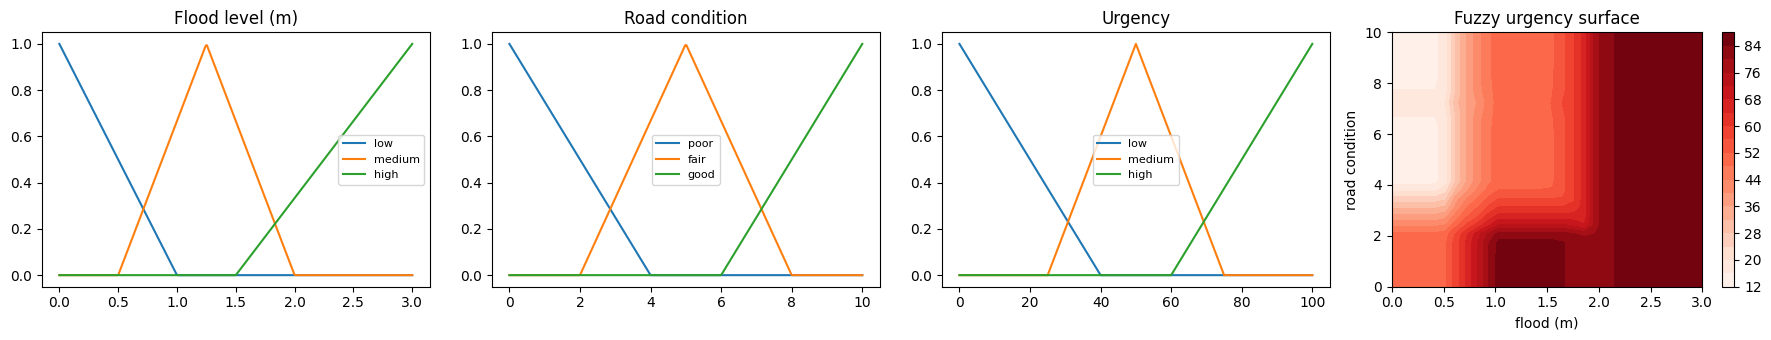

,road,condition,reports,prior,posterior,ground_usable
11,A3-J2,2.0,"[(True, 0.8), (True, 0.6)]",0.40,0.80,False
12,A3-A6,3.0,"[(True, 0.8)]",0.35,0.68,False
5,Marina-A3,3.0,"[(True, 0.7), (True, 0.6)]",0.35,0.65,False
8,A1-S1,3.0,"[(True, 0.7)]",0.35,0.56,True
6,Marina-J2,5.0,[],0.25,0.25,True
4,Marina-A2,5.0,[],0.25,0.25,True
10,A2-J2,4.0,"[(True, 0.6), (False, 0.7)]",0.30,0.22,True
22,S2-J4,7.0,[],0.15,0.15,True


,flood_est,road_est,urgency,priority,weight,actions,actions_before
A1,2.236074,4.5,84.4,critical,7.376,"[dispatch_medical, road_evacuation]","[dispatch_medical, road_evacuation]"
A2,1.518317,4.666667,50.5,medium,3.01,"[dispatch_medical, scheduled_evacuation]","[dispatch_medical, scheduled_evacuation]"
A3,2.695694,2.666667,86.3,critical,7.452,"[airlift_injured, boat_or_air_rescue, dispatch...","[dispatch_medical, road_evacuation]"
A4,0.88165,7.333333,43.2,low,1.432,[scheduled_evacuation],[scheduled_evacuation]
A5,1.236074,7.0,50.0,high,4.5,"[dispatch_medical, road_evacuation]","[dispatch_medical, road_evacuation]"
A6,0.440825,5.333333,15.1,low,1.151,[scheduled_evacuation],[scheduled_evacuation]


Prove A3 needs boat/air rescue now: True


In [23]:
apply_uncertainty(W0)

fig, axs = plt.subplots(1, 4, figsize=(18, 3.5))
mfs = [('Flood level (m)', FLOOD_MF, np.linspace(0, 3, 300)),
       ('Road condition', ROAD_MF, np.linspace(0, 10, 300)),
       ('Urgency', URG_MF, U)]
for ax, (title, sets, xs) in zip(axs, mfs):
    for k, p in sets.items():
        ax.plot(xs, trimf(xs, *p), label=k)
    ax.set_title(title)
    ax.legend(fontsize=8)
F, RC = np.meshgrid(np.linspace(0, 3, 30), np.linspace(0, 10, 30))
Z = np.vectorize(fuzzy_urgency)(F, RC)
cs = axs[3].contourf(F, RC, Z, levels=20, cmap='Reds')
plt.colorbar(cs, ax=axs[3])
axs[3].set(title='Fuzzy urgency surface', xlabel='flood (m)', ylabel='road condition')
plt.tight_layout()
plt.show()

roads = pd.DataFrame([dict(road=f'{u}-{v}', condition=e['condition'], reports=e['reports'], prior=round(e['prior'], 2),
                           posterior=round(e['p_blocked'], 2), ground_usable=e['p_blocked'] <= 0.6)
                      for u, v, e in W0['G'].edges(data=True)])
display(roads.sort_values('posterior', ascending=False).head(8))

before = {a: d['actions'] for a, d in W0['areas'].items()}
reason(W0)   # re-run rules with posterior beliefs + fuzzy urgency
tab = pd.DataFrame(W0['areas']).T[['flood_est', 'road_est', 'urgency', 'priority', 'weight', 'actions']]
tab['actions_before'] = pd.Series(before)
display(tab)
print('Prove A3 needs boat/air rescue now:', backward_chain(('action', 'A3', 'boat_or_air_rescue'), derive_facts(W0), RULES))

## 4. Resource Allocation
Shelters are assigned with a **transportation LP**: minimise travel time, respect shelter capacity, and penalise unserved people by priority.

In [24]:
def edge_time(e, speed):
    '''Minutes to traverse a road; poor or uncertain roads are slower.'''
    return 60 * e['dist'] / (speed * (0.4 + 0.06 * e['condition'])) * (1 + e['p_blocked'])

def _route(w, team, src, dst):
    if src == dst:
        return 0.0, 0.0, [src]
    if team['kind'] == 'heli':                     # straight line + take-off/landing
        km = math.dist(NODES[src][:2], NODES[dst][:2])
        return 60 * km / team['speed'] + 5, km, [src, dst]
    boat = team['kind'] == 'boat'
    H = team_graph(w, 'boat' if boat else 'ground')
    if boat:
        wfn = lambda u, v, e: 60 * e['dist'] / team['speed']
    else:
        wfn = lambda u, v, e: edge_time(e, team['speed'])
    try:
        t, path = nx.single_source_dijkstra(H, src, dst, weight=wfn)
    except nx.NetworkXNoPath:
        return math.inf, math.inf, None
    return t, sum(w['G'][a][b]['dist'] for a, b in zip(path, path[1:])), path

def route(w, team, src, dst):
    '''(minutes, km, path) for a team; cached per world state.'''
    key = (team['kind'], team['speed'], src, dst)
    if key not in w['_cache']:
        w['_cache'][key] = _route(w, team, src, dst)
    return w['_cache'][key]

def allocate_shelters(w, people):
    areas = [a for a in w['areas'] if people.get(a, 0) > 0]
    shel = [s for s, d in w['shelters'].items() if d['open'] and d['remaining'] > 0]
    if not areas or not shel:
        return {}, {a: people[a] for a in areas}, pd.DataFrame(), pd.DataFrame()
    nA, nS = len(areas), len(shel)
    nv = nA * nS
    T = np.full((nA, nS), math.inf)
    for i, a in enumerate(areas):
        for j, s in enumerate(shel):
            ground = [route(w, tm, a, s)[0] for tm in w['teams'].values() if tm['kind'] != 'heli']
            air = [route(w, tm, a, s)[0] for tm in w['teams'].values() if tm['kind'] == 'heli']
            T[i, j] = min(ground) if np.isfinite(min(ground)) else min(air + [math.inf])
    W = np.array([PRIORITY_W[w['areas'][a]['priority']] for a in areas])
    c = np.concatenate([np.where(np.isfinite(T), T, 0).ravel(), 1000.0 * W])
    bounds = [(0, None) if np.isfinite(t) else (0, 0) for t in T.ravel()] + [(0, None)] * nA
    A_eq = np.zeros((nA, nv + nA))
    for i in range(nA):
        A_eq[i, i * nS:(i + 1) * nS] = 1
        A_eq[i, nv + i] = 1                        # unserved slack
    A_ub = np.zeros((nS, nv + nA))
    for j in range(nS):
        A_ub[j, j:nv:nS] = 1
    res = linprog(c, A_ub=A_ub, b_ub=[w['shelters'][s]['remaining'] for s in shel],
                  A_eq=A_eq, b_eq=[people[a] for a in areas], bounds=bounds, method='highs')
    x = np.rint(res.x[:nv]).reshape(nA, nS).astype(int)
    alloc = {(a, s): int(x[i, j]) for i, a in enumerate(areas) for j, s in enumerate(shel) if x[i, j] > 0}
    unmet = {a: max(0, int(people[a] - x[i].sum())) for i, a in enumerate(areas)}
    return alloc, unmet, pd.DataFrame(x, index=areas, columns=shel), pd.DataFrame(T.round(1), index=areas, columns=shel)

Reference travel time area -> shelter (min):


,S1,S2,S3,S4
A1,13.3,14.5,25.8,19.0
A2,17.0,17.7,24.6,22.3
A3,44.3,31.3,29.1,41.5
A4,6.5,7.6,18.9,12.2
A5,14.2,7.6,14.4,12.2
A6,20.0,11.9,8.7,17.9


People allocated to shelters:


,S1,S2,S3,S4
A1,220,0,0,0
A2,0,300,0,0
A3,0,50,130,0
A4,130,120,0,0
A5,0,130,0,70
A6,0,0,120,0


Unserved: {'A1': 0, 'A2': 0, 'A3': 0, 'A4': 0, 'A5': 0, 'A6': 0}


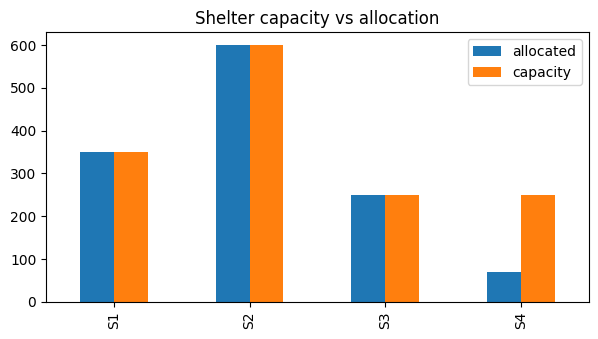

In [25]:
people0 = {a: d['population'] for a, d in W0['areas'].items()}
alloc0, unmet0, X0, T0 = allocate_shelters(W0, people0)
print('Reference travel time area -> shelter (min):')
display(T0)
print('People allocated to shelters:')
display(X0)
print('Unserved:', unmet0)

cap = pd.Series({s: d['capacity'] for s, d in W0['shelters'].items()})
pd.DataFrame({'allocated': X0.sum(), 'capacity': cap}).plot.bar(figsize=(7, 3.5), title='Shelter capacity vs allocation')
plt.show()

## 5. Multi-Agent Coordination: Contract Net Protocol
The coordinator announces tasks, teams bid (completion time + lateness + fuel), and the lowest bid wins.

Conflicts over the same team, the fuel pool or medical kits are resolved by **task priority**.

In [26]:
CHUNK, LOAD = 60, 5   # max people per task, loading time (min)

def make_tasks(w, alloc):
    '''Split each area->shelter flow into a medical task (injured) + evacuation chunks.'''
    tasks, left = [], {a: d['injured_left'] for a, d in w['areas'].items()}
    for (a, s), n in sorted(alloc.items(), key=lambda kv: -kv[1]):
        d = w['areas'][a]
        m = min(left[a], n)
        left[a] -= m
        parts = ([('medical', m)] if m else []) + [('evac', min(CHUNK, n - m - k)) for k in range(0, n - m, CHUNK)]
        for kind, size in parts:
            tasks.append(dict(id=f'K{len(tasks):02d}', area=a, shelter=s, kind=kind, people=size,
                              priority=d['priority'], weight=round(d['weight'], 2), deadline=d['deadline'],
                              kits=size if kind == 'medical' else 0))
    return tasks

class RescueAgent:
    '''Contractor agent (one rescue team).'''
    def __init__(self, tid, spec):
        self.id, self.spec = tid, spec
        self.loc, self.free_at = spec['base'], 0.0

    def bid(self, w, task):
        if task['kind'] == 'medical' and not self.spec['medical']:
            return None
        t1, k1, _ = route(w, self.spec, self.loc, task['area'])
        t2, k2, path = route(w, self.spec, task['area'], task['shelter'])
        if math.isinf(t1) or math.isinf(t2):
            return None
        n = math.ceil(task['people'] / self.spec['capacity'])
        finish = self.free_at + t1 + n * (LOAD + t2) + (n - 1) * t2
        km = k1 + (2 * n - 1) * k2
        fuel = km * self.spec['fuel_per_km']
        cost = finish + 2 * max(0, finish - task['deadline']) + 0.1 * fuel
        return dict(agent=self.id, cost=round(cost, 1), start=self.free_at, finish=finish,
                    t1=t1, t2=t2, trips=n, km=km, fuel=fuel, path=path)

    def execute(self, task, b):
        trips, t, left, kits = [], b['start'] + b['t1'], task['people'], task['kits']
        for _ in range(b['trips']):
            n = min(self.spec['capacity'], left)
            left -= n
            k = min(n, kits)
            kits -= k
            pickup = t + LOAD
            arrive = pickup + b['t2']
            trips.append(dict(agent=self.id, kind=self.spec['kind'], area=task['area'], shelter=task['shelter'],
                              people=n, pickup=pickup, arrive=arrive, deadline=task['deadline'],
                              medical=task['kind'] == 'medical', kits=k, path=b['path'],
                              km=b['km'] / b['trips'], busy=(b['finish'] - b['start']) / b['trips']))
            t = arrive + b['t2']                   # drive back empty
        self.loc, self.free_at = task['shelter'], b['finish']
        return trips

def contract_net(w, tasks, agents, max_rounds=200):
    '''Announce -> bid -> award, in rounds; conflicts resolved by task priority.'''
    open_tasks = sorted(tasks, key=lambda t: (-t['weight'], t['deadline']))
    trips, log, contracts = [], [], []
    for rnd in range(1, max_rounds + 1):
        if not open_tasks:
            break
        bids = {t['id']: sorted([b for b in (ag.bid(w, t) for ag in agents.values()) if b], key=lambda b: b['cost'])
                for t in open_tasks}
        busy, won = set(), set()
        for t in open_tasks:                        # higher priority is awarded first
            cands = bids[t['id']]
            free = [b for b in cands if b['agent'] not in busy]
            if not free:
                continue
            pool = w['resources']['fuel']
            ok = [b for b in free if b['fuel'] <= pool]
            if not ok:
                log.append(dict(round=rnd, task=t['id'], type='fuel conflict', detail=f'no free team can be fuelled ({pool:.0f} L left)'))
                continue
            best, b = cands[0], ok[0]
            if b is not best:
                ba, bb = best['agent'], b['agent']
                if ba in busy and b['cost'] > 1.3 * best['cost']:
                    log.append(dict(round=rnd, task=t['id'], type='team conflict', detail=f'{ba} busy with higher-priority task -> task waits'))
                    continue
                why = 'busy with higher-priority task' if ba in busy else 'lacks shared fuel'
                log.append(dict(round=rnd, task=t['id'], type='team conflict' if ba in busy else 'fuel conflict',
                                detail=f'{ba} {why} -> awarded to {bb}'))
            if t['kits'] > w['resources']['medical_kits']:
                need, have = t['kits'], w['resources']['medical_kits']
                log.append(dict(round=rnd, task=t['id'], type='kit conflict', detail=f'needs {need} kits, {have} left (higher priority served first)'))
                t['kits'] = have
            w['resources']['fuel'] -= b['fuel']
            w['resources']['medical_kits'] -= t['kits']
            busy.add(b['agent'])
            won.add(t['id'])
            trips += agents[b['agent']].execute(t, b)
            contracts.append(dict(round=rnd, task=t['id'], area=t['area'], shelter=t['shelter'], kind=t['kind'],
                                  people=t['people'], priority=t['priority'], winner=b['agent'], n_bids=len(cands),
                                  start=round(b['start'], 1), finish=round(b['finish'], 1)))
        if not won:
            break
        open_tasks = [t for t in open_tasks if t['id'] not in won]
    return trips, log, contracts, open_tasks

def gantt(trips, w, ax, title):
    ids = list(w['teams'])
    cmap = dict(zip(w['areas'], plt.cm.tab10.colors))
    for tr in trips:
        failed = tr.get('status') == 'failed'
        ax.barh(ids.index(tr['agent']), tr['arrive'] - tr['pickup'] + LOAD, left=tr['pickup'] - LOAD,
                color=cmap[tr['area']], edgecolor='red' if failed else 'k',
                hatch='//' if tr['medical'] else None, alpha=0.35 if failed else 1)
    ax.set_yticks(range(len(ids)))
    ax.set_yticklabels([w['teams'][t]['name'] for t in ids])
    ax.legend(handles=[Patch(color=c, label=a) for a, c in cmap.items()], ncol=6, fontsize=8, loc='upper right')
    ax.set(xlabel='time (min)', title=title)

,id,area,shelter,kind,people,priority,weight,deadline,kits
0,K00,A2,S2,medical,5,medium,3.01,360,5
1,K01,A2,S2,evac,60,medium,3.01,360,0
2,K02,A2,S2,evac,60,medium,3.01,360,0
3,K03,A2,S2,evac,60,medium,3.01,360,0
4,K04,A2,S2,evac,60,medium,3.01,360,0
5,K05,A2,S2,evac,55,medium,3.01,360,0
6,K06,A1,S1,medical,12,critical,7.38,180,12
7,K07,A1,S1,evac,60,critical,7.38,180,0
8,K08,A1,S1,evac,60,critical,7.38,180,0
9,K09,A1,S1,evac,60,critical,7.38,180,0


Call for proposals: {'id': 'K11', 'area': 'A3', 'shelter': 'S3', 'kind': 'medical', 'people': 8, 'priority': 'critical'}


,agent,cost,trips,finish,fuel
0,H1,26.0,1,21.3,47.0


Awarded contracts:


,round,task,area,shelter,kind,people,priority,winner,n_bids,start,finish
0,1,K11,A3,S3,medical,8,critical,H1,1,0.0,21.3
1,1,K12,A3,S3,evac,60,critical,B1,4,0.0,168.4
2,1,K13,A3,S3,evac,60,critical,B2,4,0.0,168.4
3,1,K28,A3,S2,evac,50,critical,B3,4,0.0,179.6
4,1,K07,A1,S1,evac,60,critical,T3,8,0.0,46.0
5,1,K10,A1,S1,evac,28,critical,T1,8,0.0,40.9
6,1,K18,A5,S2,medical,3,high,M1,2,0.0,21.2
7,1,K21,A5,S2,evac,7,high,T2,8,0.0,25.2
8,2,K14,A3,S3,evac,2,critical,H1,4,21.3,41.6
9,2,K06,A1,S1,medical,12,critical,M1,2,21.2,85.5


Conflicts resolved:


,round,task,type,detail
0,1,K13,team conflict,B1 busy with higher-priority task -> awarded t...
1,1,K14,team conflict,H1 busy with higher-priority task -> task waits
2,1,K28,team conflict,B1 busy with higher-priority task -> awarded t...
3,1,K06,team conflict,H1 busy with higher-priority task -> task waits
4,1,K08,team conflict,T3 busy with higher-priority task -> task waits
...,...,...,...,...
60,5,K25,team conflict,T3 busy with higher-priority task -> task waits
61,6,K22,team conflict,T3 busy with higher-priority task -> awarded t...
62,6,K23,team conflict,T3 busy with higher-priority task -> awarded t...
63,6,K24,team conflict,T3 busy with higher-priority task -> awarded t...


Unassigned tasks: [] | resources left: {'fuel': 122.8, 'medical_kits': 0}


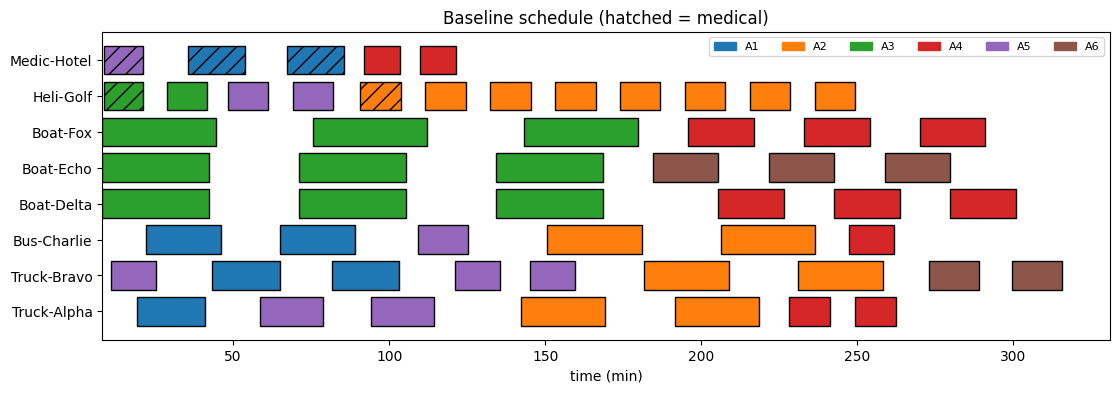

In [27]:
agents0 = {t: RescueAgent(t, s) for t, s in W0['teams'].items()}
tasks0 = make_tasks(W0, alloc0)
display(pd.DataFrame(tasks0))

top = max(tasks0, key=lambda t: t['weight'])
print('Call for proposals:', {k: top[k] for k in ('id', 'area', 'shelter', 'kind', 'people', 'priority')})
bids = [b for b in (ag.bid(W0, top) for ag in agents0.values()) if b]
display(pd.DataFrame(bids)[['agent', 'cost', 'trips', 'finish', 'fuel']].round(1).sort_values('cost'))

trips0, log0, contracts0, left0 = contract_net(W0, tasks0, agents0)
print('Awarded contracts:')
display(pd.DataFrame(contracts0))
print('Conflicts resolved:')
display(pd.DataFrame(log0) if log0 else 'none')
print('Unassigned tasks:', [t['id'] for t in left0], '| resources left:', {k: round(v, 1) for k, v in W0['resources'].items()})

fig, ax = plt.subplots(figsize=(13, 4))
gantt(trips0, W0, ax, 'Baseline schedule (hatched = medical)')
plt.show()

## 6. Simulation & Evaluation
Scenarios: baseline, severe flood, and two **unexpected events** at t = 60 min (busiest road blocked or busiest shelter closed).

*Static* keeps the original plan. *Adaptive* re-runs the full pipeline from the event time.

In [28]:
EVENT_T = 60   # time of unexpected event (min)

def plan(w, agents, people):
    '''Full pipeline: uncertainty -> rules -> shelter LP -> Contract Net.'''
    apply_uncertainty(w)
    reason(w)
    alloc, unmet, _, _ = allocate_shelters(w, people)
    trips, log, contracts, left = contract_net(w, make_tasks(w, alloc), agents)
    return dict(trips=trips, log=log, contracts=contracts, unmet=unmet, unassigned=left)

def edges_of(path):
    return {tuple(sorted(e)) for e in zip(path, path[1:])}

def inject_event(w, agents, trips, event, T, adaptive):
    future = [tr for tr in trips if tr['arrive'] > T]
    if event == 'block_route':                     # busiest remaining road collapses
        use = {}
        for tr in future:
            if tr['kind'] != 'heli':
                for e in edges_of(tr['path']):
                    use[e] = use.get(e, 0) + tr['people']
        if not use:
            return trips, dict(event=event, target=None)
        target = max(use, key=use.get)
        w['G'].edges[target]['closed'] = True
        hit = lambda tr: tr['kind'] != 'heli' and target in edges_of(tr['path'])
    else:                                          # busiest shelter becomes unavailable
        load = {}
        for tr in future:
            load[tr['shelter']] = load.get(tr['shelter'], 0) + tr['people']
        if not load:
            return trips, dict(event=event, target=None)
        target = max(load, key=load.get)
        w['shelters'][target]['open'] = False
        hit = lambda tr: tr['shelter'] == target
    info = dict(event=event, target=target, affected_people=sum(tr['people'] for tr in future if hit(tr)))

    if not adaptive:                               # static plan: affected trips fail
        for tr in future:
            if hit(tr):
                tr['status'] = 'failed'
        return trips, info

    # adaptive: keep finished and unaffected in-transit trips, re-plan the rest
    kept = [tr for tr in trips if tr['arrive'] <= T or (tr['pickup'] <= T and not hit(tr))]
    keep_ids = {id(tr) for tr in kept}
    cancelled = [tr for tr in trips if id(tr) not in keep_ids]
    for ag in agents.values():
        mine = [tr for tr in kept if tr['agent'] == ag.id]
        last = max(mine, key=lambda tr: tr['arrive']) if mine else None
        ag.loc = last['shelter'] if last else ag.spec['base']
        ag.free_at = max(T, last['arrive']) if last else T
        stuck = [tr for tr in cancelled if tr['agent'] == ag.id and tr['pickup'] <= T]
        if stuck:                                  # turned back mid-route
            ag.loc, ag.free_at = stuck[0]['area'], T + 10
    for s, d in w['shelters'].items():
        d['remaining'] = d['capacity'] - sum(tr['people'] for tr in kept if tr['shelter'] == s)
    people = {}
    for a, d in w['areas'].items():
        people[a] = d['population'] - sum(tr['people'] for tr in kept if tr['area'] == a)
        d['injured_left'] = max(0, d['injured'] - sum(tr['people'] for tr in kept if tr['area'] == a and tr['medical']))
    w['resources'] = dict(fuel=RESOURCES['fuel'] - sum(tr['km'] * w['teams'][tr['agent']]['fuel_per_km'] for tr in kept),
                          medical_kits=RESOURCES['medical_kits'] - sum(tr['kits'] for tr in kept))
    out = plan(w, agents, people)
    for tr in out['trips']:
        tr['status'] = 'done'
    info.update(replanned_people=sum(people.values()), new_contracts=len(out['contracts']), conflicts=len(out['log']))
    return kept + out['trips'], info

def run_scenario(severity=0.0, event=None, adaptive=True, T=EVENT_T):
    w = make_world(severity)
    agents = {t: RescueAgent(t, s) for t, s in w['teams'].items()}
    out = plan(w, agents, {a: d['population'] for a, d in w['areas'].items()})
    for tr in out['trips']:
        tr['status'] = 'done'
    trips, info = out['trips'], dict(conflicts=len(out['log']))
    if event:
        trips, info = inject_event(w, agents, trips, event, T, adaptive)
    return dict(w=w, trips=trips, info=info)

def evaluate(w, trips, label):
    df = pd.DataFrame(trips)
    total = sum(d['population'] for d in w['areas'].values())
    ok = df[df['status'] == 'done']
    safe = ok[ok['arrive'] <= ok['deadline']]
    span = ok['arrive'].max()
    fuel = sum(r.km * w['teams'][r.agent]['fuel_per_km'] for r in df.itertuples())
    return dict(scenario=label, people=total, evacuated=int(ok['people'].sum()), safe=int(safe['people'].sum()),
                stranded=int(total - ok['people'].sum()), makespan_min=round(span, 1),
                avg_evac_min=round(float(np.average(ok['arrive'], weights=ok['people'])), 1),
                fuel_L=round(fuel, 1), kits_used=int(ok['kits'].sum()),
                team_util=round(df['busy'].sum() / (len(w['teams']) * span), 2),
                shelter_util=round(ok['people'].sum() / sum(d['capacity'] for d in w['shelters'].values()), 2))

def evac_curve(trips):
    df = pd.DataFrame(trips)
    df = df[df['status'] == 'done'].sort_values('arrive')
    return df['arrive'].values, df['people'].cumsum().values

In [29]:
SCENARIOS = {
    'Baseline':         dict(severity=0.0),
    'Severe':           dict(severity=0.7),
    'Block-static':     dict(severity=0.7, event='block_route', adaptive=False),
    'Block-adaptive':   dict(severity=0.7, event='block_route', adaptive=True),
    'Shelter-static':   dict(severity=0.7, event='shelter_closed', adaptive=False),
    'Shelter-adaptive': dict(severity=0.7, event='shelter_closed', adaptive=True),
}

RUNS, rows = {}, []
for name, cfg in SCENARIOS.items():
    RUNS[name] = run_scenario(**cfg)
    rows.append(evaluate(RUNS[name]['w'], RUNS[name]['trips'], name))
    print(f'{name:17s}', RUNS[name]['info'])

results = pd.DataFrame(rows).set_index('scenario')
display(results)

Baseline          {'conflicts': 65}
Severe            {'conflicts': 64}
Block-static      {'event': 'block_route', 'target': ('J3', 'S2'), 'affected_people': 510}
Block-adaptive    {'event': 'block_route', 'target': ('J3', 'S2'), 'affected_people': 510, 'replanned_people': 1088, 'new_contracts': 22, 'conflicts': 53}
Shelter-static    {'event': 'shelter_closed', 'target': 'S2', 'affected_people': 570}
Shelter-adaptive  {'event': 'shelter_closed', 'target': 'S2', 'affected_people': 570, 'replanned_people': 1088, 'new_contracts': 16, 'conflicts': 29}


,people,evacuated,safe,stranded,makespan_min,avg_evac_min,fuel_L,kits_used,team_util,shelter_util
scenario,,,,,,,,,,
Baseline,1270,1270,1270,0,315.6,165.9,777.2,25,0.82,0.88
Severe,1270,1270,1178,0,301.1,171.1,798.9,25,0.94,0.88
Block-static,1270,760,748,510,283.1,147.4,798.9,25,1.01,0.52
Block-adaptive,1270,1270,924,0,455.7,198.9,781.3,25,0.66,0.88
Shelter-static,1270,700,700,570,283.1,143.8,798.9,25,1.01,0.48
Shelter-adaptive,1270,880,672,390,336.2,164.3,680.3,25,0.73,0.61


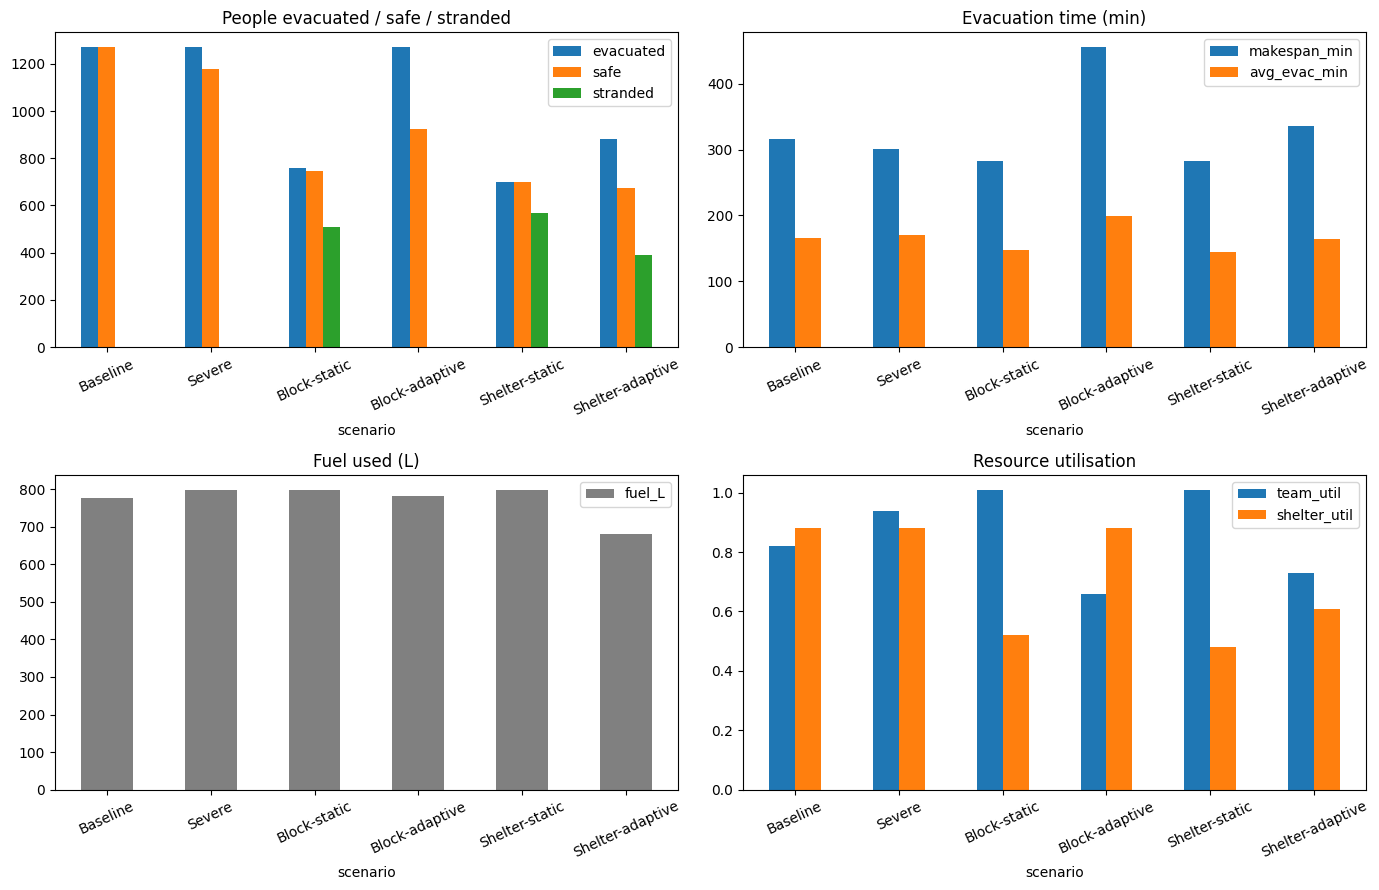

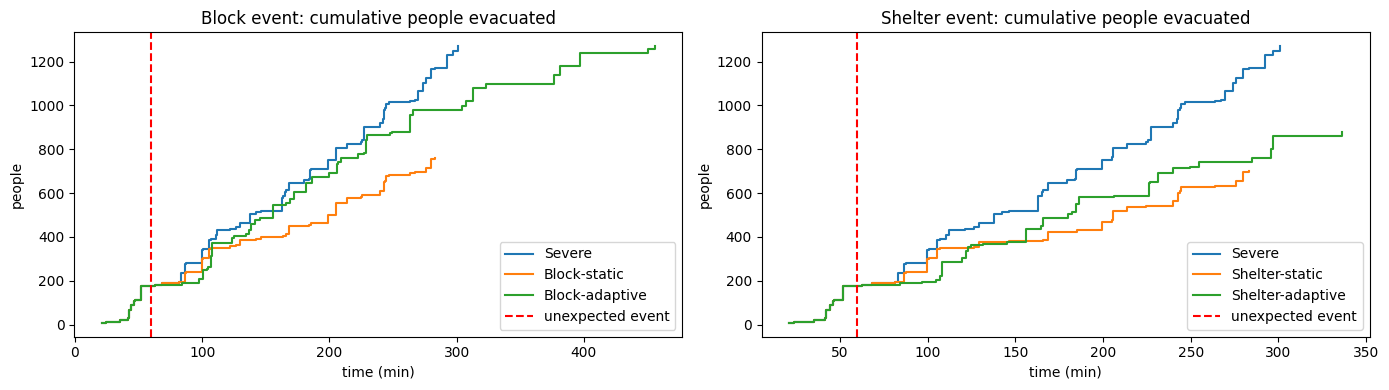

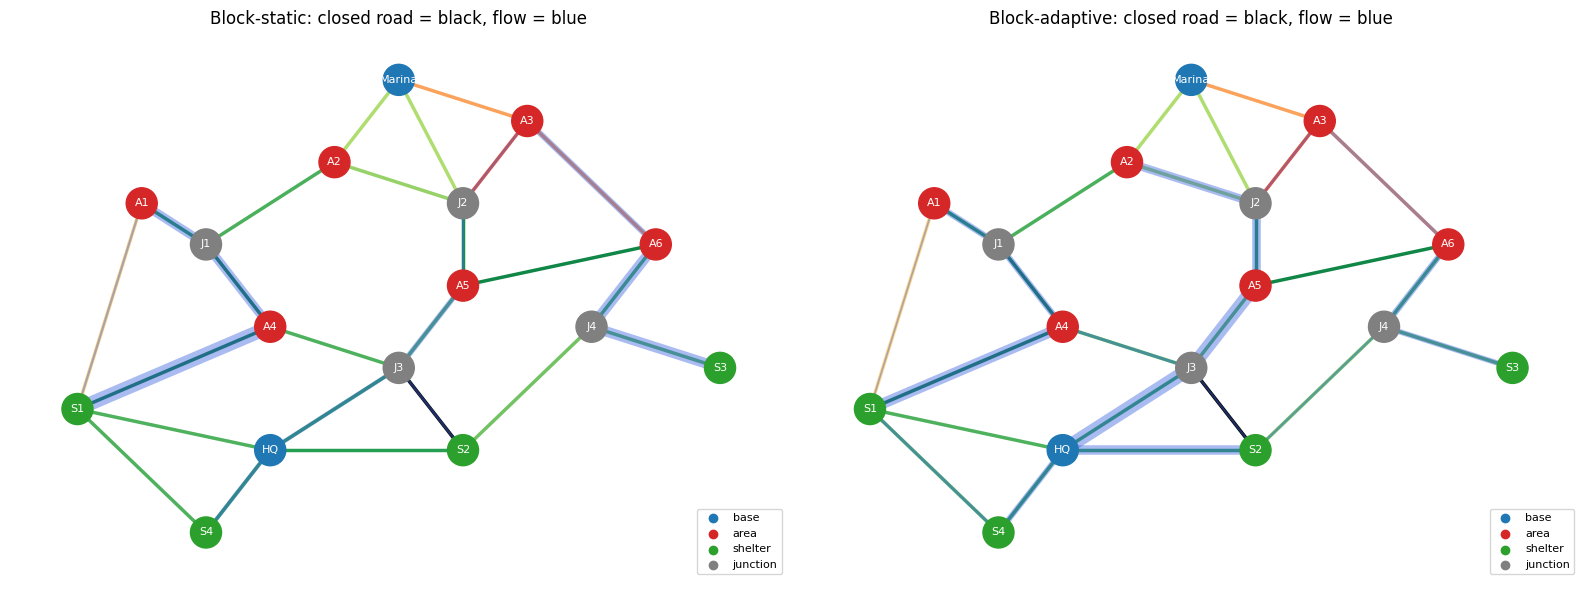

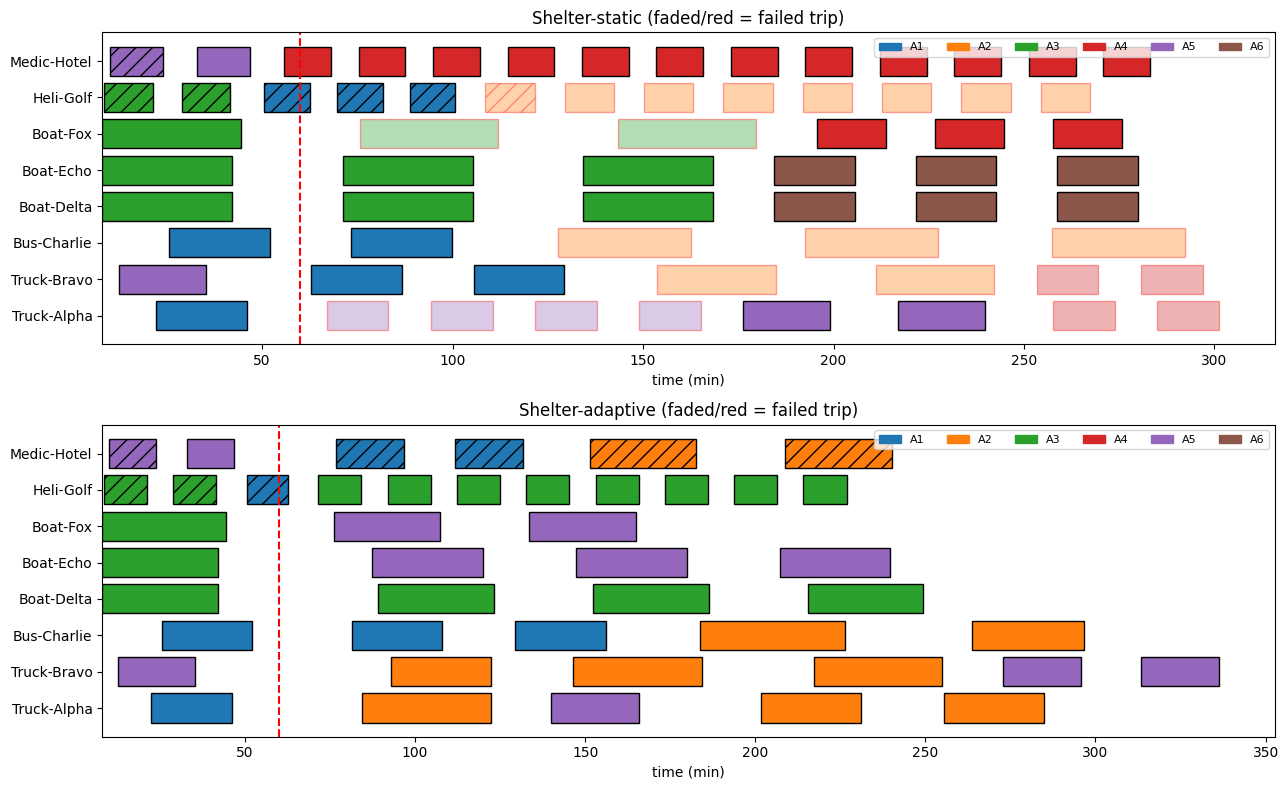

In [30]:
# Metric comparison
fig, axs = plt.subplots(2, 2, figsize=(14, 9))
results[['evacuated', 'safe', 'stranded']].plot.bar(ax=axs[0, 0], title='People evacuated / safe / stranded')
results[['makespan_min', 'avg_evac_min']].plot.bar(ax=axs[0, 1], title='Evacuation time (min)')
results[['fuel_L']].plot.bar(ax=axs[1, 0], title='Fuel used (L)', color='gray')
results[['team_util', 'shelter_util']].plot.bar(ax=axs[1, 1], title='Resource utilisation')
for ax in axs.flat:
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

# Cumulative evacuation curves
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for ax, ev in zip(axs, ['Block', 'Shelter']):
    for name in ['Severe', ev + '-static', ev + '-adaptive']:
        x, y = evac_curve(RUNS[name]['trips'])
        ax.step(x, y, where='post', label=name)
    ax.axvline(EVENT_T, color='red', ls='--', label='unexpected event')
    ax.set(title=f'{ev} event: cumulative people evacuated', xlabel='time (min)', ylabel='people')
    ax.legend()
plt.tight_layout()
plt.show()

# Route flows before/after adaptation (blocked road)
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
for ax, name in zip(axs, ['Block-static', 'Block-adaptive']):
    r = RUNS[name]
    done = [t for t in r['trips'] if t['status'] == 'done']
    draw_map(r['w'], ax, f'{name}: closed road = black, flow = blue', trips=done)
plt.tight_layout()
plt.show()

# Schedules for the shelter-closure event
fig, axs = plt.subplots(2, 1, figsize=(13, 8))
for ax, name in zip(axs, ['Shelter-static', 'Shelter-adaptive']):
    gantt(RUNS[name]['trips'], RUNS[name]['w'], ax, f'{name} (faded/red = failed trip)')
    ax.axvline(EVENT_T, color='red', ls='--')
plt.tight_layout()
plt.show()

### Observations
- **Severity:** a severe flood raises urgency, blocks more roads, shifts work to boats and the helicopter, and creates conflicts over medical kits and fuel.
- **Blocked route:** the static plan loses the trips that used the road. The adaptive plan re-routes them, so more people are evacuated, with some extra time and fuel.
- **Closed shelter:** the static plan strands people headed there. The adaptive plan re-runs the LP over the remaining capacity.
- **Conclusion:** adaptive re-planning (rules + fuzzy/Bayes + LP + CNP) evacuates more people safely after unexpected events.